# Đánh giá thực nghiệm
- Kết quả đã lưu cho 24 mô hình × 2 tập validation, gồm MCF và UP-Fall.
- Với tập gộp, cộng hai confusion matrix rồi tính lại chỉ số.
- Chạy lại đánh giá khi đã tải checkpoint và trích feature trên toàn bộ ảnh.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display
from PIL import Image, ImageOps

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "papercode").is_dir())
paper = root / "papercode"
prepare = paper / "prepare-dataset"
postures = ["Đi/đứng", "Nằm", "Đang ngã", "Ngồi"]

In [2]:
import json

evaluation = paper / "eval"
benchmark = pd.read_csv(evaluation / "benchmark.csv")
matrices = pd.DataFrame(json.loads((evaluation / "confusion_matrices.json").read_text(encoding="utf-8")))
columns = ["train_source", "target", "feature", "family", "accuracy", "f1_macro", "p3_recall"]
print(f"{len(benchmark)} lượt đánh giá")
display(benchmark[columns].sort_values(["train_source", "target", "f1_macro"],
                                       ascending=[True, True, False]).round(4))

48 lượt đánh giá


,train_source,target,feature,family,accuracy,f1_macro,p3_recall
8,mcf,mcf,resnet50,knn,0.9626,0.9125,0.6014
0,mcf,mcf,hog,knn,0.9630,0.9112,0.5873
6,mcf,mcf,hog,svm_rbf,0.9628,0.9106,0.5660
14,mcf,mcf,resnet50,svm_rbf,0.9614,0.9070,0.5401
10,mcf,mcf,resnet50,linear_svc,0.9545,0.8945,0.5330
12,mcf,mcf,resnet50,softmax,0.9519,0.8945,0.5708
4,mcf,mcf,hog,softmax,0.9164,0.7999,0.3467
2,mcf,mcf,hog,linear_svc,0.9196,0.7849,0.2406
9,mcf,upfall,resnet50,knn,0.5527,0.3238,0.0667
5,mcf,upfall,hog,softmax,0.2731,0.2309,0.2211


## Confusion matrix và chỉ số

Accuracy: 98.02%
Macro-F1: 93.52% | Recall P3: 65.02%


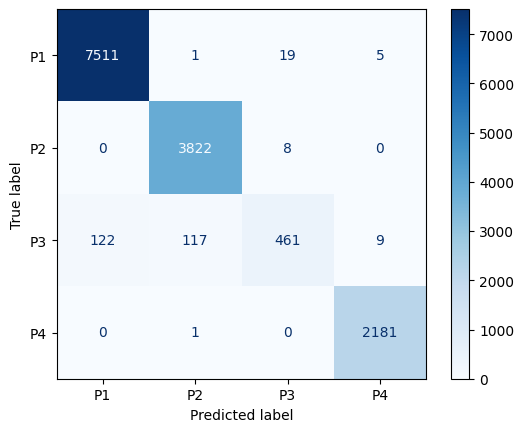

In [3]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

train_source = "mix"
target = "mix"  # mcf, upfall hoặc mix
model_id = "hog_svm_rbf"
rows = matrices[matrices.train_source.eq(train_source) & matrices.model.eq(model_id)]
if target != "mix":
    rows = rows[rows.target.eq(target)]
cm = np.asarray(rows["values"].tolist()).sum(axis=0)
true_positive = cm.diagonal()
f1 = 2 * true_positive / np.maximum(cm.sum(axis=0) + cm.sum(axis=1), 1)
recall = true_positive / np.maximum(cm.sum(axis=1), 1)
print(f"Accuracy: {true_positive.sum() / cm.sum():.2%}")
print(f"Macro-F1: {f1.mean():.2%} | Recall P3: {recall[2]:.2%}")
ConfusionMatrixDisplay(cm, display_labels=["P1", "P2", "P3", "P4"]).plot(values_format="d", cmap="Blues")
plt.show()

## Tùy chọn nạp checkpoint để dự đoán lại

In [4]:
import hashlib

import joblib
from sklearn.metrics import classification_report, confusion_matrix

RUN_PREDICTION = False
if RUN_PREDICTION:
    models = evaluation / "models"
    index = json.loads((models / "index.json").read_text(encoding="utf-8"))
    model_info = index["models"][train_source][model_id]
    with (models / model_info["path"]).open("rb") as file:
        if hashlib.file_digest(file, "sha256").hexdigest() != model_info["sha256"]:
            raise ValueError("Checkpoint không khớp SHA-256 trong index.json")
    model = joblib.load(models / model_info["path"])["model"]
    feature = model_id.split("_", 1)[0]
    true, predicted = [], []
    for dataset in ("mcf", "upfall") if target == "mix" else (target,):
        split = pd.read_csv(prepare / f"splits/{dataset}.csv")
        vectors = np.load(prepare / f"prepared/features/{dataset}_{feature}.npy", mmap_mode="r")
        ids = np.flatnonzero(split.split.eq("validation"))
        true.extend(split.label.to_numpy()[ids])
        for start in range(0, len(ids), 512):
            predicted.extend(model.predict(vectors[ids[start:start + 512]]))
    print(classification_report(true, predicted, labels=range(4), target_names=postures, digits=4))
    display(pd.DataFrame(confusion_matrix(true, predicted, labels=range(4)),
                         index=postures, columns=postures))